In [3]:
!unzip -q georgia_ecg_data/georgia-12lead-ecg-challenge-database.zip \
    -d georgia_ecg_data

In [4]:
!pip install wfdb pandas numpy scipy scikit-learn matplotlib seaborn tqdm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 448.1 kB/s eta 0:00:00


In [24]:
!nvidia-smi

Sun Sep 20 12:01:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P0             57W /  400W |   16840MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
import os
import gc
import glob
import random
import warnings
from collections import Counter
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scipy.signal import butter, sosfiltfilt, iirnotch, tf2sos, resample_poly
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
import wfdb

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass


In [ ]:
class Config:

    DATA_PATH = "georgia_ecg_data"

    ORIGINAL_SAMPLING_RATE = 500
    SAMPLING_RATE = 500
    DOWNSAMPLE_FACTOR = ORIGINAL_SAMPLING_RATE // SAMPLING_RATE
    SIGNAL_DURATION_SEC = 10
    SIGNAL_LENGTH = SAMPLING_RATE * SIGNAL_DURATION_SEC   # 5000 samples

    NUM_LEADS = 12
    LEAD_NAMES = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']

    BANDPASS_LOW  = 0.5
    BANDPASS_HIGH = 40.0
    BANDPASS_ORDER = 4

    NOTCH_FREQS = [50.0]
    NOTCH_Q = 30.0


    NUM_LABELS = 30
    MIN_SAMPLES_PER_LABEL = 50

    # Georgia has no official stratified-fold column like PTB-XL's strat_fold,
    # so we reproduce the same ~80/10/10 proportions with a fixed seed instead.
    TRAIN_FRAC = 0.8
    VAL_FRAC   = 0.1
    TEST_FRAC  = 0.1

    DX_MAPPING_SOURCES = {
        "scored": "https://raw.githubusercontent.com/physionetchallenges/evaluation-2020/master/dx_mapping_scored.csv",
        "unscored": "https://raw.githubusercontent.com/physionetchallenges/evaluation-2020/master/dx_mapping_unscored.csv",
    }

    AUG_PROB = 0.5
    AUG_GAUSSIAN_NOISE_STD = 0.05
    AUG_AMPLITUDE_SCALE_RANGE = (0.9, 1.1)
    AUG_TIME_SHIFT_MAX = 100
    AUG_LEAD_DROPOUT_PROB = 0.2
    AUG_LEAD_DROPOUT_MAX_LEADS = 2

    BATCH_SIZE = 32

    CLASS_WEIGHT_MIN = 0.5
    CLASS_WEIGHT_MAX = 10.0


cfg = Config()

print("=" * 60)
print("Georgia 12-Lead ECG Preprocessing Pipeline — 30 Labels")
print("=" * 60)
print(f"Data path        : {cfg.DATA_PATH}")
print(f"Native rate      : {cfg.ORIGINAL_SAMPLING_RATE} Hz")
print(f"Target rate      : {cfg.SAMPLING_RATE} Hz (downsample factor {cfg.DOWNSAMPLE_FACTOR})")
print(f"Signal length    : {cfg.SIGNAL_LENGTH} samples (10 s @ {cfg.SAMPLING_RATE} Hz)")
print(f"Leads            : {cfg.NUM_LEADS}")
print(f"Target labels    : {cfg.NUM_LABELS}")
print(f"Minimum frequency: {cfg.MIN_SAMPLES_PER_LABEL} records per label")


Georgia 12-Lead ECG Preprocessing Pipeline — 30 Labels
Data path        : georgia_ecg_data
Native rate      : 500 Hz
Target rate      : 500 Hz (downsample factor 1)
Signal length    : 5000 samples (10 s @ 500 Hz)
Leads            : 12
Target labels    : 30
Minimum frequency: 50 records per label


In [ ]:
# ============================================================
# 1. Discover records + parse .hea headers (Dx codes, age, sex, fs, siglen)
# ============================================================

import os, glob, tarfile, zipfile, re
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

def extract_nested_archives(root):
    '''Some PhysioNet Kaggle mirrors ship the raw .tar.gz/.zip shards as-is
    instead of pre-extracted .hea/.mat files. Auto-extract any we find, one
    level, so the recursive glob below can pick up the WFDB files.'''
    found_archive = False
    for dirpath, _, filenames in os.walk(root):
        for fn in filenames:
            full = os.path.join(dirpath, fn)
            lower = fn.lower()
            try:
                if lower.endswith(".tar.gz") or lower.endswith(".tgz"):
                    found_archive = True
                    print(f"  Extracting {full} ...")
                    with tarfile.open(full, "r:gz") as tf:
                        tf.extractall(dirpath)
                elif lower.endswith(".tar"):
                    found_archive = True
                    print(f"  Extracting {full} ...")
                    with tarfile.open(full, "r:") as tf:
                        tf.extractall(dirpath)
                elif lower.endswith(".zip"):
                    found_archive = True
                    print(f"  Extracting {full} ...")
                    with zipfile.ZipFile(full, "r") as zf:
                        zf.extractall(dirpath)
            except Exception as e:
                print(f"  [WARN] failed to extract {full}: {e}")
    return found_archive


def find_header_files(data_path):
    
    hea_files = glob.glob(os.path.join(data_path, "**", "*.hea"), recursive=True)
    hea_files += glob.glob(os.path.join(data_path, "**", "*.HEA"), recursive=True)
    hea_files = sorted(set(hea_files))

    if not hea_files:
        print("No .hea files found on first pass -- checking for nested archives ...")
        if extract_nested_archives(data_path):
            hea_files = glob.glob(os.path.join(data_path, "**", "*.hea"), recursive=True)
            hea_files += glob.glob(os.path.join(data_path, "**", "*.HEA"), recursive=True)
            hea_files = sorted(set(hea_files))

    print(f"Found {len(hea_files)} .hea header files under '{data_path}'")
    if not hea_files:
        print("  Still nothing. Run the DIAGNOSTIC cell above and check the")
        print("  'Top-level contents' / extension counts to find the real path,")
        print("  then update cfg.DATA_PATH accordingly.")
    return hea_files


def parse_header(hea_path):

    record_path = hea_path[:-4]  
    dx_codes, age, sex = [], np.nan, np.nan

    with open(hea_path, "r") as f:
        lines = [l.rstrip("\n").rstrip("\r") for l in f.readlines()]

    header0 = lines[0].split()
    n_sig = int(header0[1])
    fs = float(header0[2])
    siglen = int(header0[3])

    gains, baselines, sig_names = [], [], []
    gain_re = re.compile(r'(?P<gain>-?[\d.]+)(\((?P<baseline>-?[\d.]+)\))?/(?P<units>\S+)')

    for i in range(1, n_sig + 1):
        parts = lines[i].split()
        gain_field = parts[2] if len(parts) > 2 else "1000/mV"
        m = gain_re.match(gain_field)
        gain = float(m.group("gain")) if m and m.group("gain") else 1000.0
        baseline = float(m.group("baseline")) if (m and m.group("baseline")) else 0.0
        if gain == 0:
            gain = 1000.0
        gains.append(gain)
        baselines.append(baseline)
        sig_names.append(parts[-1])

    for line in lines:
        line = line.strip()
        if line.startswith("#Age"):
            val = line.split(":", 1)[1].strip()
            age = float(val) if val.replace(".", "", 1).isdigit() else np.nan
        elif line.startswith("#Sex"):
            val = line.split(":", 1)[1].strip().lower()
            if val.startswith("m"):
                sex = 1.0
            elif val.startswith("f"):
                sex = 0.0
            else:
                sex = np.nan
        elif line.startswith("#Dx"):
            val = line.split(":", 1)[1].strip()
            dx_codes = [c.strip() for c in val.split(",") if c.strip()]

    return {
        "record_path": record_path,
        "record_id": os.path.basename(record_path),
        "dx_codes": dx_codes,
        "age": age,
        "sex": sex,
        "gains": gains,
        "baselines": baselines,
        "sig_names": sig_names,
        "fs": fs,
        "siglen": siglen,
    }


def load_georgia_metadata(data_path):
    print("\n[1/8] Loading Georgia header metadata ...")
    hea_files = find_header_files(data_path)
    records = [parse_header(h) for h in tqdm(hea_files, desc="Parsing headers")]
    df = pd.DataFrame(records)
    print("Total records:", len(df))
    return df


df_meta = load_georgia_metadata(cfg.DATA_PATH)
df_meta.head()



[1/8] Loading Georgia header metadata ...
Found 10344 .hea header files under 'georgia_ecg_data'


Parsing headers:   0%|          | 0/10344 [00:00<?, ?it/s]

Total records: 10344


,record_path,record_id,dx_codes,age,sex,gains,baselines,sig_names,fs,siglen
0,georgia_ecg_data/Georgia/E00001,E00001,[426783006],NaN,0.0,"[4880.0, 4880.0, 4880.0, 4880.0, 4880.0, 4880....","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5...",500.0,5000
1,georgia_ecg_data/Georgia/E00002,E00002,[426783006],NaN,0.0,"[4880.0, 4880.0, 4880.0, 4880.0, 4880.0, 4880....","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5...",500.0,5000
2,georgia_ecg_data/Georgia/E00003,E00003,[426783006],NaN,1.0,"[4880.0, 4880.0, 4880.0, 4880.0, 4880.0, 4880....","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5...",500.0,5000
3,georgia_ecg_data/Georgia/E00004,E00004,"[426177001, 425623009, 164934002, 164873001]",75.0,1.0,"[4880.0, 4880.0, 4880.0, 4880.0, 4880.0, 4880....","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5...",500.0,5000
4,georgia_ecg_data/Georgia/E00005,E00005,"[59118001, 164889003]",83.0,1.0,"[4880.0, 4880.0, 4880.0, 4880.0, 4880.0, 4880....","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5...",500.0,5000


In [ ]:
# ============================================================
# 2. Map SNOMED-CT Dx codes 
# ============================================================
import pandas as pd

def load_dx_mappings(mapping_sources):
    print("\n[2/8] Loading official SNOMED-CT diagnosis mappings ...")
    mapping_frames = []

    for source_name, url in mapping_sources.items():
        dx_map = pd.read_csv(url)

        code_col = [c for c in dx_map.columns if "snomed" in c.lower()][0]
        abbr_col = [c for c in dx_map.columns if "abbrev" in c.lower()][0]

        part = dx_map[[code_col, abbr_col]].copy()
        part.columns = ["code", "abbreviation"]
        part = part.dropna(subset=["code", "abbreviation"])
        part["code"] = part["code"].astype(str).str.replace(r"\.0$", "", regex=True)
        part["abbreviation"] = part["abbreviation"].astype(str)
        part["mapping_source"] = source_name
        mapping_frames.append(part)
        print(f"  {source_name.capitalize():8s}: {len(part)} codes")

    combined_map = pd.concat(mapping_frames, ignore_index=True)
    combined_map = combined_map.drop_duplicates(subset="code", keep="first")
    code_to_abbr = dict(zip(combined_map["code"], combined_map["abbreviation"]))

    print(f"  Combined : {len(code_to_abbr)} unique SNOMED-CT codes")
    return code_to_abbr, combined_map


code_to_abbr, dx_mapping = load_dx_mappings(cfg.DX_MAPPING_SOURCES)


def map_dx_to_labels(df, code_to_abbr):
    def get_labels(codes):
        return {code_to_abbr[str(c)] for c in codes if str(c) in code_to_abbr}

    df = df.copy()
    df["labels"] = df["dx_codes"].apply(get_labels)
    return df


df_meta = map_dx_to_labels(df_meta, code_to_abbr)
df_meta[["record_id", "dx_codes", "labels"]].head()



[2/8] Loading official SNOMED-CT diagnosis mappings ...
  Scored  : 27 codes
  Unscored: 84 codes
  Combined : 111 unique SNOMED-CT codes


,record_id,dx_codes,labels
0,E00001,[426783006],{NSR}
1,E00002,[426783006],{NSR}
2,E00003,[426783006],{NSR}
3,E00004,"[426177001, 425623009, 164934002, 164873001]","{TAb, LVH, LIs, SB}"
4,E00005,"[59118001, 164889003]","{AF, RBBB}"



[3/8] Selecting the 30 most frequent diagnosis labels ...
  Before filtering: 10344 records
  After removing unmapped records: 10344 records
  After removing missing age/sex: 10267 records
  Selected labels (30): ['TAb', 'NSSTTA', 'NSR', 'SB', 'LQT', 'STach', 'LVH', 'STIAb', 'LAD', 'LIs', 'LAE', 'TInv', 'IAVB', 'PAC', 'AF', 'RBBB', 'QAb', 'SA', 'IIs', 'IRBBB', 'LQRSV', 'VPB', 'AnMIs', 'LBBB', 'NSIVCB', 'AFL', 'LAnFB', 'ERe', 'STE', 'BBB']
  Final class distribution: {'TAb': 2290, 'NSSTTA': 1861, 'NSR': 1732, 'SB': 1671, 'LQT': 1380, 'STach': 1252, 'LVH': 1232, 'STIAb': 989, 'LAD': 937, 'LIs': 901, 'LAE': 866, 'TInv': 806, 'IAVB': 767, 'PAC': 636, 'AF': 568, 'RBBB': 538, 'QAb': 455, 'SA': 454, 'IIs': 447, 'IRBBB': 405, 'LQRSV': 369, 'VPB': 356, 'AnMIs': 275, 'LBBB': 231, 'NSIVCB': 203, 'AFL': 185, 'LAnFB': 177, 'ERe': 140, 'STE': 134, 'BBB': 116}
  Remaining records: 10211


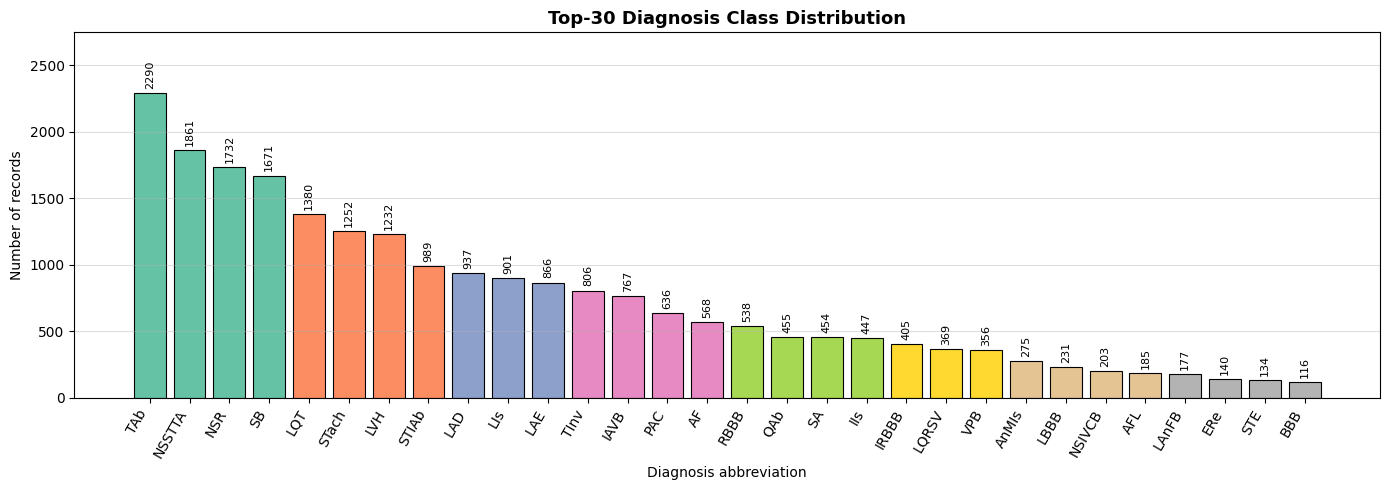

In [ ]:
from collections import Counter
import matplotlib.pyplot as plt

def select_top_labels(df, num_labels=30, min_samples=50):
    print(f"\n[3/8] Selecting the {num_labels} most frequent diagnosis labels ...")
    print(f"  Before filtering: {len(df)} records")

    df = df[df["labels"].apply(len) > 0].copy()
    print(f"  After removing unmapped records: {len(df)} records")

    df = df[df["age"].notna() & df["sex"].notna()].copy()
    print(f"  After removing missing age/sex: {len(df)} records")

    all_counts = Counter(label for labels in df["labels"] for label in labels)
    eligible = [(label, count) for label, count in all_counts.items()
                if count >= min_samples]
    eligible.sort(key=lambda item: (-item[1], item[0]))

    if len(eligible) < num_labels:
        raise ValueError(
            f"Only {len(eligible)} labels have at least {min_samples} records; "
            f"cannot select {num_labels}. Lower MIN_SAMPLES_PER_LABEL."
        )

    selected_labels = [label for label, _ in eligible[:num_labels]]
    selected_set = set(selected_labels)

    df["labels"] = df["labels"].apply(lambda labels: labels & selected_set)
    df = df[df["labels"].apply(len) > 0].copy()

    label_counts = Counter(label for labels in df["labels"] for label in labels)
    label_counts = dict(sorted(label_counts.items(),
                               key=lambda item: (-item[1], item[0])))

    if len(label_counts) != num_labels:
        raise RuntimeError(
            f"Expected {num_labels} final labels, but found {len(label_counts)}."
        )

    print(f"  Selected labels ({len(selected_labels)}): {selected_labels}")
    print(f"  Final class distribution: {label_counts}")
    print(f"  Remaining records: {len(df)}")

    return df.reset_index(drop=True), label_counts


df_meta, label_counts = select_top_labels(
    df_meta,
    num_labels=cfg.NUM_LABELS,
    min_samples=cfg.MIN_SAMPLES_PER_LABEL,
)


def plot_class_distribution(label_counts, title="Top-30 Diagnosis Class Distribution"):
    fig, ax = plt.subplots(figsize=(14, 5))
    classes_, counts_ = list(label_counts.keys()), list(label_counts.values())
    colors = plt.cm.Set2(np.linspace(0, 1, len(classes_)))
    bars = ax.bar(classes_, counts_, color=colors, edgecolor='black', linewidth=0.8)
    ax.bar_label(bars, fmt='%d', padding=3, fontsize=8, rotation=90)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel("Diagnosis abbreviation")
    ax.set_ylabel("Number of records")
    ax.set_ylim(0, max(counts_) * 1.20)
    ax.grid(axis='y', alpha=0.4)
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.savefig("viz_01_class_distribution_top30.png", dpi=150)
    plt.show()


plot_class_distribution(label_counts)


In [ ]:
# ============================================================
# 3. Load raw signals 
# ============================================================
import gc
import numpy as np
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, iirnotch, tf2sos, resample_poly
from tqdm.auto import tqdm

def build_filters(fs, lowcut, highcut, order, notch_freqs, Q):
    nyq = 0.5 * fs
    sos_bp = butter(order, [lowcut / nyq, highcut / nyq], btype="band", output="sos")
    notch_filters = [tf2sos(*iirnotch(freq, Q, fs=fs)) for freq in notch_freqs]
    return sos_bp, notch_filters


def load_raw_signal(row, cfg):

    mat_path = row.record_path + ".mat"
    mat = loadmat(mat_path)
    raw = mat["val"].astype(np.float64)          # shape (n_sig, siglen)

    gains = np.asarray(row.gains, dtype=np.float64).reshape(-1, 1)
    baselines = np.asarray(row.baselines, dtype=np.float64).reshape(-1, 1)
    physical = (raw - baselines) / gains          # (n_sig, siglen), mV
    physical = physical.T                          # (siglen, n_sig)

    sig_names = list(row.sig_names)
    if set(cfg.LEAD_NAMES).issubset(set(sig_names)):
        order_idx = [sig_names.index(l) for l in cfg.LEAD_NAMES]
        physical = physical[:, order_idx]

    return physical.astype(np.float32)


def load_filter_resample(df, cfg):
    print("\n[4/8] Loading + filtering (500 Hz) + resampling (-> 100 Hz) ...")

    sos_bp, notch_filters = build_filters(
        cfg.ORIGINAL_SAMPLING_RATE, cfg.BANDPASS_LOW, cfg.BANDPASS_HIGH,
        cfg.BANDPASS_ORDER, cfg.NOTCH_FREQS, cfg.NOTCH_Q
    )

    N = len(df)
    X = np.zeros((N, cfg.SIGNAL_LENGTH, cfg.NUM_LEADS), dtype=np.float32)
    keep_mask = np.ones(N, dtype=bool)
    n_failed = 0

    for i, row in enumerate(tqdm(df.itertuples(), total=N, desc="Processing ECG")):
        try:
            sig = load_raw_signal(row, cfg)

            if sig.shape[1] != cfg.NUM_LEADS:
                raise ValueError(f"expected {cfg.NUM_LEADS} leads, got {sig.shape[1]}")

            # Bandpass + notch at native 500 Hz
            sig = sosfiltfilt(sos_bp, sig, axis=0)
            for notch in notch_filters:
                sig = sosfiltfilt(notch, sig, axis=0)

         
            sig = resample_poly(sig, up=1, down=cfg.DOWNSAMPLE_FACTOR, axis=0)

            n = sig.shape[0]
            if n >= cfg.SIGNAL_LENGTH:
                sig = sig[:cfg.SIGNAL_LENGTH]
            else:
                pad = np.zeros((cfg.SIGNAL_LENGTH - n, cfg.NUM_LEADS), dtype=np.float32)
                sig = np.vstack([sig, pad])

            X[i] = sig.astype(np.float32)

        except Exception as e:
            n_failed += 1
            if n_failed <= 20:
                print(f"  [WARN] skipping {row.record_id}: {e}")
            elif n_failed == 21:
                print("  [WARN] further per-file warnings suppressed ...")
            keep_mask[i] = False

        if i % 1000 == 0:
            gc.collect()

    print(f"Filtering + resampling complete. Output: {X.shape} ({n_failed} records failed / skipped)")
    return X, keep_mask


X_filtered, keep_mask = load_filter_resample(df_meta, cfg)


df_meta = df_meta[keep_mask].reset_index(drop=True)
X_filtered = X_filtered[keep_mask]

print("Final aligned shapes:", df_meta.shape, X_filtered.shape)

output_dir = "/content/drive/MyDrive/GeorgiaECG/"
os.makedirs(output_dir, exist_ok=True)
np.save(os.path.join(output_dir, "X_filtered_100hz.npy"), X_filtered)
print("Saved filtered/resampled array.")



[4/8] Loading + filtering (500 Hz) + resampling (-> 100 Hz) ...


Processing ECG:   0%|          | 0/10211 [00:00<?, ?it/s]

Filtering + resampling complete. Output: (10211, 5000, 12) (0 records failed / skipped)
Final aligned shapes: (10211, 11) (10211, 5000, 12)
Saved filtered/resampled array.


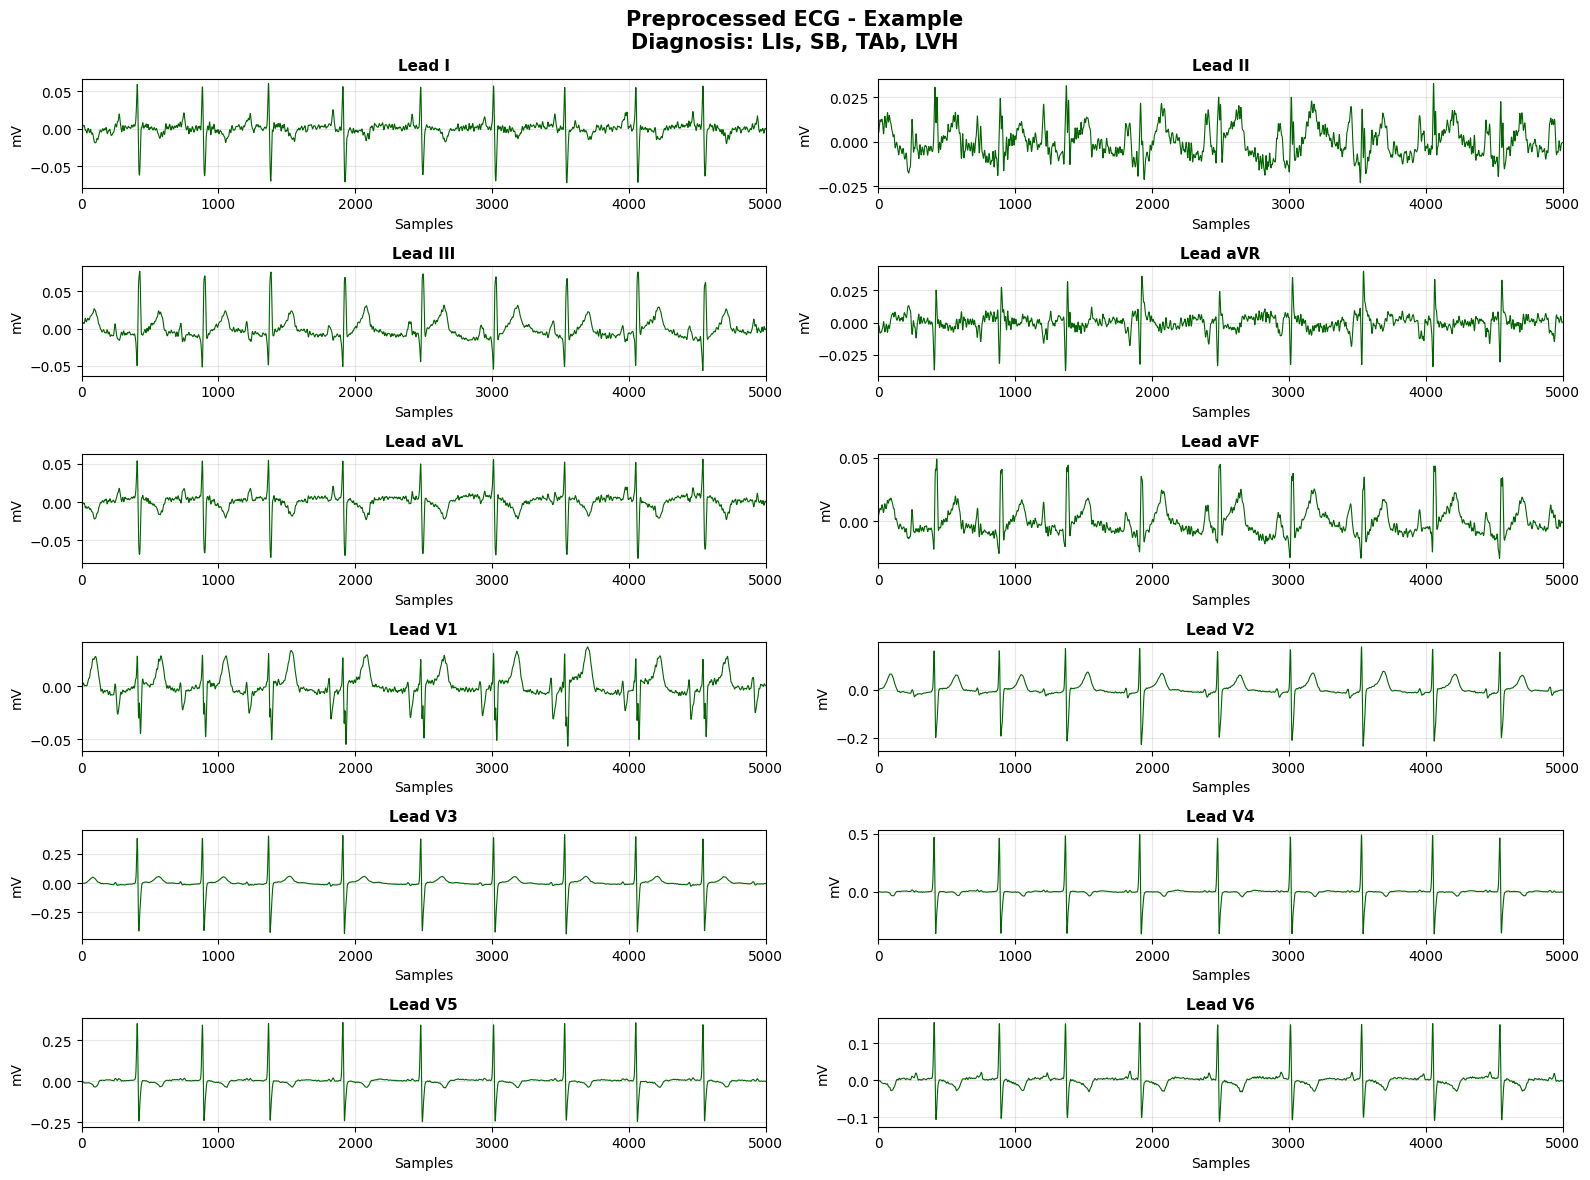

In [ ]:
# ============================================================
# Visualize
# ============================================================
def plot_ecg(signal, labels, title="ECG Signal"):
    fig, axes = plt.subplots(6, 2, figsize=(16, 12))
    axes = axes.flatten()
    for i in range(12):
        axes[i].plot(signal[:, i], linewidth=0.8, color="darkgreen")
        axes[i].set_title(f"Lead {cfg.LEAD_NAMES[i]}", fontsize=11, fontweight="bold")
        axes[i].set_xlim(0, signal.shape[0])
        axes[i].set_xlabel("Samples"); axes[i].set_ylabel("mV")
        axes[i].grid(alpha=0.3)
    diagnosis = ", ".join(list(labels))
    fig.suptitle(f"{title}\nDiagnosis: {diagnosis}", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()

if len(df_meta) > 0:
    idx = 0
    plot_ecg(X_filtered[idx], df_meta.iloc[idx]["labels"], title="Preprocessed ECG - Example")


In [12]:
# ============================================================
# 4. Split (Georgia has no official strat_fold, so we reproduce the same
#    ~80/10/10 proportions as PTB-XL's folds 1-8/9/10 with a fixed seed)
# ============================================================
import numpy as np
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.model_selection import train_test_split

def split_georgia(df, X, cfg):
    print("\n[5/8] Splitting Georgia dataset (80/10/10, seed = %d)..." % SEED)

    idx_all = np.arange(len(df))

    idx_train, idx_temp = train_test_split(
        idx_all, train_size=cfg.TRAIN_FRAC, random_state=SEED, shuffle=True
    )
    rel_val_frac = cfg.VAL_FRAC / (cfg.VAL_FRAC + cfg.TEST_FRAC)
    idx_val, idx_test = train_test_split(
        idx_temp, train_size=rel_val_frac, random_state=SEED, shuffle=True
    )

    X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]

    y_train_labels = df.loc[idx_train, "labels"]
    y_val_labels   = df.loc[idx_val,   "labels"]
    y_test_labels  = df.loc[idx_test,  "labels"]

    # Patient data: age (StandardScaler on train) + sex (already 0/1)
    patient_data_train = df.loc[idx_train, ['age', 'sex']].values.astype(np.float32)
    patient_data_val   = df.loc[idx_val,   ['age', 'sex']].values.astype(np.float32)
    patient_data_test  = df.loc[idx_test,  ['age', 'sex']].values.astype(np.float32)

    scaler = StandardScaler()
    patient_data_train[:, 0] = scaler.fit_transform(patient_data_train[:, 0].reshape(-1, 1)).flatten()
    patient_data_val[:, 0]   = scaler.transform(patient_data_val[:, 0].reshape(-1, 1)).flatten()
    patient_data_test[:, 0]  = scaler.transform(patient_data_test[:, 0].reshape(-1, 1)).flatten()

    classes = sorted(list(set(label for group in df["labels"] for label in group)))

    mlb = MultiLabelBinarizer(classes=classes)
    y_train = mlb.fit_transform(y_train_labels)
    y_val   = mlb.transform(y_val_labels)
    y_test  = mlb.transform(y_test_labels)

    print("Classes:", classes)
    print("Train:", X_train.shape, patient_data_train.shape, y_train.shape)
    print("Val  :", X_val.shape, patient_data_val.shape, y_val.shape)
    print("Test :", X_test.shape, patient_data_test.shape, y_test.shape)

    masks = {"train": idx_train, "val": idx_val, "test": idx_test}
    return (X_train, X_val, X_test, patient_data_train, patient_data_val, patient_data_test,
            y_train, y_val, y_test, classes, mlb, masks)


(X_train, X_val, X_test, patient_data_train, patient_data_val, patient_data_test,
 y_train, y_val, y_test, classes, mlb, masks) = split_georgia(df_meta, X_filtered, cfg)



[5/8] Splitting Georgia dataset (80/10/10, seed = 42)...
Classes: ['AF', 'AFL', 'AnMIs', 'BBB', 'ERe', 'IAVB', 'IIs', 'IRBBB', 'LAD', 'LAE', 'LAnFB', 'LBBB', 'LIs', 'LQRSV', 'LQT', 'LVH', 'NSIVCB', 'NSR', 'NSSTTA', 'PAC', 'QAb', 'RBBB', 'SA', 'SB', 'STE', 'STIAb', 'STach', 'TAb', 'TInv', 'VPB']
Train: (8168, 5000, 12) (8168, 2) (8168, 30)
Val  : (1021, 5000, 12) (1021, 2) (1021, 30)
Test : (1022, 5000, 12) (1022, 2) (1022, 30)


In [ ]:
# ============================================================
# 5. Dataset verification 
# ============================================================
def verify_dataset(df, masks, y_train, y_val, y_test, classes):
    print("\n[6/8] Verifying dataset ...")
    train_idx, val_idx, test_idx = set(masks["train"]), set(masks["val"]), set(masks["test"])

    assert train_idx.isdisjoint(val_idx), "train/val overlap!"
    assert train_idx.isdisjoint(test_idx), "train/test overlap!"
    assert val_idx.isdisjoint(test_idx), "val/test overlap!"
    assert len(train_idx | val_idx | test_idx) == len(df), "splits do not cover all records!"
    print("[PASS] train/val/test index sets are disjoint and cover the full dataset.")

    dist = pd.DataFrame({
        "train": y_train.mean(axis=0) * 100,
        "val": y_val.mean(axis=0) * 100,
        "test": y_test.mean(axis=0) * 100,
    }, index=classes).round(2)
    print("\nPer-split positive rate (%) by class:")
    print(dist)
    return dist

verify_dataset(df_meta, masks, y_train, y_val, y_test, classes)



[6/8] Verifying dataset ...
[PASS] train/val/test index sets are disjoint and cover the full dataset.

Per-split positive rate (%) by class:
        train    val   test
AF       5.44   5.39   6.75
AFL      1.84   1.76   1.66
AnMIs    2.47   3.53   3.62
BBB      1.10   1.27   1.27
ERe      1.47   1.08   0.88
IAVB     7.57   8.03   6.56
IIs      4.43   3.72   4.60
IRBBB    3.95   3.62   4.40
LAD      9.52   7.44   8.12
LAE      8.36   8.91   9.00
LAnFB    1.64   2.45   1.76
LBBB     2.28   1.96   2.45
LIs      8.79   8.91   9.00
LQRSV    3.61   3.82   3.42
LQT     13.20  14.01  15.56
LVH     12.22  11.75  11.15
NSIVCB   1.98   1.96   2.05
NSR     16.93  16.36  17.81
NSSTTA  17.98  20.86  17.51
PAC      6.26   5.88   6.36
QAb      4.31   4.31   5.77
RBBB     5.15   6.76   4.70
SA       4.32   4.60   5.28
SB      16.50  17.43  14.19
STE      1.32   1.27   1.27
STIAb    9.32  11.36  10.96
STach   12.34  12.14  11.74
TAb     22.26  22.72  23.48
TInv     7.77   8.81   7.93
VPB      3.43   3.

,train,val,test
AF,5.44,5.39,6.75
AFL,1.84,1.76,1.66
AnMIs,2.47,3.53,3.62
BBB,1.10,1.27,1.27
ERe,1.47,1.08,0.88
IAVB,7.57,8.03,6.56
IIs,4.43,3.72,4.60
IRBBB,3.95,3.62,4.40
LAD,9.52,7.44,8.12
LAE,8.36,8.91,9.00


In [14]:
def calculate_train_stats(X_train):
    print("\nCalculating train normalization parameters...")
    mean = X_train.mean(axis=(0, 1))
    std  = X_train.std(axis=(0, 1))
    std[std == 0] = 1e-8
    print("Mean shape:", mean.shape)
    print("STD shape :", std.shape)
    return mean, std


def normalize_data(X, mean, std):
    return ((X - mean) / std).astype(np.float32)


lead_mean, lead_std = calculate_train_stats(X_train)

X_train = normalize_data(X_train, lead_mean, lead_std)
X_val   = normalize_data(X_val,   lead_mean, lead_std)
X_test  = normalize_data(X_test,  lead_mean, lead_std)

print("Normalization completed")
print(X_train.shape, X_val.shape, X_test.shape)



Calculating train normalization parameters...
Mean shape: (12,)
STD shape : (12,)
Normalization completed
(8168, 5000, 12) (1021, 5000, 12) (1022, 5000, 12)


In [ ]:
# ============================================================
# Augmentation 
# ============================================================
def augment_ecg(x):
    if tf.random.uniform([]) < cfg.AUG_PROB:
        noise = tf.random.normal(tf.shape(x), mean=0, stddev=cfg.AUG_GAUSSIAN_NOISE_STD)
        x = x + noise

    if tf.random.uniform([]) < cfg.AUG_PROB:
        lo, hi = cfg.AUG_AMPLITUDE_SCALE_RANGE
        x = x * tf.random.uniform([], lo, hi)

    if tf.random.uniform([]) < cfg.AUG_PROB:
        shift = tf.random.uniform([], -cfg.AUG_TIME_SHIFT_MAX, cfg.AUG_TIME_SHIFT_MAX, dtype=tf.int32)
        x = tf.roll(x, shift=shift, axis=0)

    if tf.random.uniform([]) < cfg.AUG_LEAD_DROPOUT_PROB:
        num_leads = tf.shape(x)[-1]
        n_drop = tf.random.uniform([], 1, cfg.AUG_LEAD_DROPOUT_MAX_LEADS + 1, dtype=tf.int32)
        drop_idx = tf.random.shuffle(tf.range(num_leads))[:n_drop]
        mask = tf.reduce_max(tf.one_hot(drop_idx, num_leads), axis=0)
        x = x * (1.0 - mask)

    return x


def make_dataset(X_ecg, X_patient, y, batch_size, training=False):
    ds = tf.data.Dataset.from_tensor_slices(((X_ecg, X_patient), y))
    if training:
        ds = ds.shuffle(len(X_ecg), reshuffle_each_iteration=True)
        ds = ds.map(lambda inputs, y: ((augment_ecg(inputs[0]), inputs[1]), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(X_train, patient_data_train, y_train, cfg.BATCH_SIZE, training=True)
val_ds   = make_dataset(X_val,   patient_data_val,   y_val,   cfg.BATCH_SIZE, training=False)
test_ds  = make_dataset(X_test,  patient_data_test,  y_test,  cfg.BATCH_SIZE, training=False)

print("Dataset pipeline ready")
print(train_ds); print(val_ds); print(test_ds)


Dataset pipeline ready
<_PrefetchDataset element_spec=((TensorSpec(shape=(None, 5000, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)), TensorSpec(shape=(None, 30), dtype=tf.int64, name=None))>
<_PrefetchDataset element_spec=((TensorSpec(shape=(None, 5000, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)), TensorSpec(shape=(None, 30), dtype=tf.int64, name=None))>
<_PrefetchDataset element_spec=((TensorSpec(shape=(None, 5000, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)), TensorSpec(shape=(None, 30), dtype=tf.int64, name=None))>


In [16]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

L2 = regularizers.l2(2e-4)


def se_block_1d(x, reduction=8, name=None):
    channels = x.shape[-1]
    se = layers.GlobalAveragePooling1D()(x)
    se = layers.Dense(max(channels // reduction, 4), activation="relu")(se)
    se = layers.Dense(channels, activation="sigmoid")(se)
    se = layers.Reshape((1, channels))(se)
    return layers.Multiply(name=name)([x, se])

def tcn_residual_block(x, filters, kernel_size, dilation_rate, dropout_rate=0.3):
    previous = x
    x = layers.Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation_rate,
                       kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation_rate,
                       kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)

    if previous.shape[-1] != filters:
        previous = layers.Conv1D(filters, 1, padding="same")(previous)

    x = layers.Add()([previous, x])
    x = layers.Activation("relu")(x)
    return x

def build_tcn(x, filters=64, kernel_size=3, num_blocks=4, dropout_rate=0.4):
    for i in range(num_blocks):
        x = tcn_residual_block(x, filters, kernel_size, dilation_rate=2 ** i, dropout_rate=dropout_rate)
    return x

def temporal_branch(signal_input):
    x = layers.Conv1D(48, kernel_size=7, padding="same", kernel_regularizer=L2)(signal_input)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv1D(96, kernel_size=5, padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(128, kernel_size=5, padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = build_tcn(x, filters=64, num_blocks=4, dropout_rate=0.3)
    x = se_block_1d(x, reduction=8, name="se_attention")
    return layers.GlobalAveragePooling1D()(x)


In [ ]:
# ============================================================
# Branch 2: Spectral branch
# ============================================================
class STFTLayer(layers.Layer):
    def __init__(self, frame_length=256, frame_step= 64, fft_length=256, **kwargs):
        super().__init__(**kwargs)
        self.frame_length = frame_length
        self.frame_step = frame_step
        self.fft_length = fft_length

    def call(self, x):
        x = tf.transpose(x, [0, 2, 1])
        spec = tf.signal.stft(x, frame_length=self.frame_length,
                               frame_step=self.frame_step, fft_length=self.fft_length)
        mag = tf.math.log1p(tf.abs(spec))
        return tf.transpose(mag, [0, 3, 2, 1])

    def compute_output_shape(self, input_shape):
        batch, time, leads = input_shape
        frames = 1 + (time - self.frame_length) // self.frame_step
        freq_bins = self.fft_length // 2 + 1
        return (batch, freq_bins, frames, leads)

def transformer_encoder_block(x, num_heads=4, key_dim=32, ff_dim=128, dropout_rate=0.3):
    attn_out = layers.MultiHeadAttention(num_heads=num_heads, key_dim=key_dim, dropout=dropout_rate)(x, x)
    x = layers.Add()([x, attn_out])
    x = layers.LayerNormalization()(x)
    ff = layers.Dense(ff_dim, activation="gelu", kernel_regularizer=L2)(x)
    ff = layers.Dense(x.shape[-1])(ff)
    ff = layers.Dropout(dropout_rate)(ff)
    x = layers.Add()([x, ff])
    x = layers.LayerNormalization()(x)
    return x

class AttentionPooling1D(layers.Layer):
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        self.score_dense1 = layers.Dense(self.units, activation="tanh")
        self.score_dense2 = layers.Dense(1)
        super().build(input_shape)

    def call(self, x):
        scores = self.score_dense2(self.score_dense1(x))
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(x * weights, axis=1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])


def spectral_branch(signal_input):
    x = STFTLayer()(signal_input)

    x = layers.Conv2D(24, (3, 3), padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D((2, 1))(x)

    x = layers.Conv2D(48, (3, 3), padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D((2, 1))(x)

    shape = x.shape
    x = layers.Reshape((shape[1] * shape[2], shape[3]))(x)
    x = transformer_encoder_block(x, num_heads=4, key_dim=32, ff_dim=128)
    return AttentionPooling1D()(x)


In [ ]:
# ============================================================
# Branch 3: Patient metadata 
# ============================================================
def patient_branch(patient_input):
    p = layers.Dense(32, activation="relu")(patient_input)
    p = layers.BatchNormalization()(p)
    p = layers.Dropout(0.2)(p)
    p = layers.Dense(16, activation="relu")(p)
    p = layers.BatchNormalization()(p)
    return p


In [ ]:

# ============================================================
# Fusion + classifier 
# ============================================================
def gated_multimodal_fusion(temporal_vec, spectral_vec, dim=96):

    t = layers.Dense(dim, activation="tanh")(temporal_vec)
    s = layers.Dense(dim, activation="tanh")(spectral_vec)

    gate_input = layers.Concatenate()([temporal_vec, spectral_vec])
    z = layers.Dense(dim, activation="sigmoid", name="fusion_gate")(gate_input)

    fused = layers.Add(name="fused_features")([
        layers.Multiply()([z, t]),

        layers.Multiply()([layers.Lambda(lambda x: 1 - x)(z), s])
    ])
    return fused

def classifier(fusion, num_classes):
    x = layers.Dense(256, kernel_regularizer=L2)(fusion)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.4)(x)

    x = layers.Dense(128, kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.3)(x)

    return layers.Dense(num_classes, activation="sigmoid", name="diagnosis_output")(x)

def build_model(signal_len, num_leads, num_classes):
    input_ecg = layers.Input(shape=(signal_len, num_leads), name="ecg_signal")
    patient_input = layers.Input(shape=(2,), name="patient_input")

    temporal = temporal_branch(input_ecg)
    spectral = spectral_branch(input_ecg)
    patient_features = patient_branch(patient_input)

    fusion = gated_multimodal_fusion(temporal, spectral)
    fusion = layers.Concatenate(name="fusion_with_patient")([fusion, patient_features])

    output = classifier(fusion, num_classes)
    return keras.Model(inputs=[input_ecg, patient_input], outputs=output, name="ECG_DualBranch_v2")


In [20]:
model = build_model(signal_len=cfg.SIGNAL_LENGTH, num_leads=cfg.NUM_LEADS, num_classes=len(classes))

model.compile(
    optimizer=tf.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss=  "binary_crossentropy",
    metrics=[
        keras.metrics.AUC(multi_label=True, name="macro_auc"),
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
    ]
)
model.summary()

Model: "ECG_DualBranch_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ecg_signal          │ (None, 5000, 12)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 5000, 48)  │      4,080 │ ecg_signal[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 5000, 48)  │        192 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 5000, 48)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 5000, 96)  │     23,136 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 5000, 96)  │        384 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 5000, 96)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 2500, 96)  │          0 │ activation_1[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 2500, 128) │     61,568 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 2500, 128) │        512 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 2500, 128) │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 1250, 128) │          0 │ activation_2[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 1250, 64)  │     24,640 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1250, 64)  │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 1250, 64)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1250, 64)  │          0 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 1250, 64)  │     12,352 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 1250, 64)  │      8,256 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1250, 64)  │        256 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 353,198 (1.35 MB)

 Trainable params: 350,622 (1.34 MB)

 Non-trainable params: 2,576 (10.06 KB)

In [21]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_macro_auc", mode="max",
                                   patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_macro_auc", mode="max",
                                       factor=0.5, patience=4, min_lr=1e-6),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=60, callbacks=callbacks, verbose=1)


Epoch 1/60
256/256 ━━━━━━━━━━━━━━━━━━━━ 58s 135ms/step - binary_accuracy: 0.8944 - loss: 0.4231 - macro_auc: 0.6012 - val_binary_accuracy: 0.9268 - val_loss: 0.3092 - val_macro_auc: 0.7401 - learning_rate: 0.0010
Epoch 2/60
256/256 ━━━━━━━━━━━━━━━━━━━━ 32s 126ms/step - binary_accuracy: 0.9326 - loss: 0.2660 - macro_auc: 0.7206 - val_binary_accuracy: 0.9306 - val_loss: 0.2452 - val_macro_auc: 0.7737 - learning_rate: 0.0010
Epoch 3/60
256/256 ━━━━━━━━━━━━━━━━━━━━ 32s 126ms/step - binary_accuracy: 0.9352 - loss: 0.2337 - macro_auc: 0.7591 - val_binary_accuracy: 0.9330 - val_loss: 0.2238 - val_macro_auc: 0.8052 - learning_rate: 0.0010
Epoch 4/60
256/256 ━━━━━━━━━━━━━━━━━━━━ 32s 126ms/step - binary_accuracy: 0.9366 - loss: 0.2175 - macro_auc: 0.7799 - val_binary_accuracy: 0.9341 - val_loss: 0.2148 - val_macro_auc: 0.8171 - learning_rate: 0.0010
Epoch 5/60
256/256 ━━━━━━━━━━━━━━━━━━━━ 32s 126ms/step - binary_accuracy: 0.9375 - loss: 0.2082 - macro_auc: 0.7877 - val_binary_accuracy: 0.9313 - 

In [22]:
from sklearn.metrics import f1_score, roc_auc_score

val_probs = model.predict(val_ds)
val_preds = (val_probs > 0.5).astype(int)

val_binary_accuracy = np.mean(y_val == val_preds)
val_macro_auc = roc_auc_score(y_val, val_probs, average="macro")

print(f"Validation Macro AUC       : {val_macro_auc:.4f}")
print(f"Validation Binary Accuracy: {val_binary_accuracy:.4f}")
print("Validation Macro F1:", f1_score(y_val, val_preds, average="macro", zero_division=0))
print("Per-class F1:", f1_score(y_val, val_preds, average=None, zero_division=0))

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step
Validation Macro AUC       : 0.9215
Validation Binary Accuracy: 0.9511
Validation Macro F1: 0.46023417298817415
Per-class F1: [0.67924528 0.18181818 0.46153846 0.36363636 0.26666667 0.75739645
 0.17777778 0.29090909 0.59898477 0.56       0.         0.8
 0.57317073 0.53521127 0.63453815 0.70742358 0.         0.81707317
 0.20472441 0.60952381 0.12244898 0.81481481 0.62337662 0.95604396
 0.         0.50549451 0.87029289 0.69491525 0.         0.        ]


In [ ]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score,
    accuracy_score, hamming_loss, classification_report
)

def evaluate_model(model, dataset, y_true, class_names, thresholds=None):

    y_prob = model.predict(dataset)
    num_classes = y_true.shape[1]

    if thresholds is None:
        thresholds = np.full(num_classes, 0.5)
    y_pred = (y_prob > thresholds).astype(int)

    results = {}

    # ---- Threshold-independent metrics (the ones that actually matter here) ----
    results["macro_auc"] = roc_auc_score(y_true, y_prob, average="macro")

    per_class_auc = roc_auc_score(y_true, y_prob, average=None)
    results["per_class_auc"] = dict(zip(class_names, per_class_auc.tolist()))

    # ---- Threshold-dependent metrics ----
    results["macro_f1"] = f1_score(y_true, y_pred, average="macro", zero_division=0)
    results["macro_precision"] = precision_score(y_true, y_pred, average="macro", zero_division=0)
    results["macro_recall"] = recall_score(y_true, y_pred, average="macro", zero_division=0)

    per_class_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    results["per_class_f1"] = dict(zip(class_names, per_class_f1.tolist()))

    results["binary_accuracy"] = np.mean(y_true == y_pred)         
    results["hamming_loss"] = hamming_loss(y_true, y_pred)             

    return results, y_prob, y_pred


def print_evaluation(results, class_names):
    print("=" * 60)
    print("Scores")
    print("=" * 60)

    print(f"Test Macro AUC       : {results['macro_auc']:.4f}")
    print(f"Test Macro F1        : {results['macro_f1']:.4f}")
    print(f"Test binary accuracy   : {results['binary_accuracy']:.4f}")
    print(f"Test Hamming loss      : {results['hamming_loss']:.4f}")


    print("\nPer-class AUC-ROC:")
    for c, v in results["per_class_auc"].items():
        print(f"  {c:8s}: {v:.4f}")

    print("\nPer-class F1:")
    for c, v in results["per_class_f1"].items():
        print(f"  {c:8s}: {v:.4f}")



# Evaluate on TEST set 
results, y_prob, y_pred = evaluate_model(model, test_ds, y_test, classes)  
print_evaluation(results, classes)

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step
Scores
Test Macro AUC       : 0.9243
Test Macro F1        : 0.4742
Test binary accuracy   : 0.9498
Test Hamming loss      : 0.0502

Per-class AUC-ROC:
  AF      : 0.9482
  AFL     : 0.9362
  AnMIs   : 0.9369
  BBB     : 0.9819
  ERe     : 0.9623
  IAVB    : 0.9625
  IIs     : 0.9312
  IRBBB   : 0.9590
  LAD     : 0.9763
  LAE     : 0.9550
  LAnFB   : 0.9490
  LBBB    : 0.9909
  LIs     : 0.9244
  LQRSV   : 0.9715
  LQT     : 0.9025
  LVH     : 0.9463
  NSIVCB  : 0.8271
  NSR     : 0.9731
  NSSTTA  : 0.8214
  PAC     : 0.9265
  QAb     : 0.9107
  RBBB    : 0.9716
  SA      : 0.9539
  SB      : 0.9921
  STE     : 0.7824
  STIAb   : 0.8884
  STach   : 0.9939
  TAb     : 0.8889
  TInv    : 0.7151
  VPB     : 0.8493

Per-class F1:
  AF      : 0.7879
  AFL     : 0.4000
  AnMIs   : 0.3200
  BBB     : 0.6154
  ERe     : 0.3333
  IAVB    : 0.7040
  IIs     : 0.0816
  IRBBB   : 0.4865
  LAD     : 0.7090
  LAE     : 0.5248
  LAnFB   : 0.0000
  LBBB    : 0.8